# Maintenance-log NLP for predictive maintenance: walkthrough

The pipeline stage by stage on the synthetic data: load the logs, clean the text, build weekly asset snapshots, compare four rankers on a time-based split, and produce the weekly watchlist.

*All data is synthetic. No plant or CMMS data is used.*

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 110)

## 1. Load the data

In [2]:
from src.data.load_data import load_data
reg, logs, failures, episodes = load_data()
print(len(reg), 'assets |', len(logs), 'log entries |', len(failures), 'breakdowns (ground truth)')
logs.sample(6, random_state=3)[['date','asset_id','source','text']]

120 assets | 19780 log entries | 359 breakdowns (ground truth)


,date,asset_id,source,text
1087,2020-04-26,P-2005,pm_task,Oil topped up.
17242,2025-03-27,P-6018A,operator_round,Guard refitted after inspection.
5888,2021-10-15,P-1010A,operator_round,lube oil looks discoloured.
12497,2023-10-23,P-2002A,operator_round,AREA HOUSEKEEPING DONE.
5606,2021-09-13,P-5026A,pm_task,"Routine round, all normal."
523,2020-02-24,P-2005,operator_round,Strainer cleaned as per PM.


## 2. Clean the text
Shorthand is expanded, asset tags are removed, and typos are repaired using the plant's own vocabulary.

In [3]:
from src.data.preprocess import clean, learn_typo_fixes
fixes = learn_typo_fixes(logs.text)
print(len(fixes), 'spelling fixes learned, e.g.', list(fixes.items())[:6])
for t in ['BRG TEMP HI on P-1001A, vib incr', 'Strainer claened as per PM.']:
    print(t, '->', clean(t, fixes))

182 spelling fixes learned, e.g. [('inuslation', 'insulation'), ('tpoped', 'topped'), ('gerased', 'greased'), ('reapir', 'repair'), ('siganl', 'signal'), ('paniting', 'painting')]
BRG TEMP HI on P-1001A, vib incr -> bearing temperature high on , vibration increasing
Strainer claened as per PM. -> strainer cleaned as per pm.


## 3-7. Weekly snapshots, four rankers, time-based test (full pipeline)

In [4]:
from src import pipeline
m, test, scores, failures, episodes, chosen = pipeline.run()
pd.DataFrame({'PR-AUC': m['test_pr_auc'], 'weekly top-10 precision': m['test_precision_at_k']})

,PR-AUC,weekly top-10 precision
Keyword count,0.155,0.197
History only (no text),0.151,0.182
"Text + history, logistic",0.366,0.301
"Text + history, LightGBM",0.380,0.327


In [5]:
pd.DataFrame(m['test_breakdowns_caught']).T

,all,with_warning_in_text,sudden,median_lead_days,false_alarms_inside_repaired_degradation
Keyword count,78 of 131,73 of 97,5 of 34,15.0,0.167
History only (no text),77 of 131,69 of 97,8 of 34,17.0,0.141
"Text + history, logistic",99 of 131,92 of 97,7 of 34,23.0,0.306
"Text + history, LightGBM",103 of 131,93 of 97,10 of 34,24.0,0.321


## The weekly watchlist

In [6]:
pd.read_csv('reports/watchlist_latest_week.csv')

,asset_id,asset_type,criticality,risk,days_since_corrective,evidence_last_60_days,actually_broke_down_within_30d
0,P-3033A,pump,C,0.945,999.0,discharge pressure fluctuating. / painting and insulation repair done.,1
1,K-5011,compressor,B,0.941,999.0,discharge temperature high. / discharge temperature high. / discharge temperature high.,1
2,P-1022,pump,C,0.898,999.0,lube oil looks discoloured. / oil topped up.,1
3,PT-3003,transmitter,A,0.890,149.0,"manifold valve leaking. / impulse line partly plugged, slow response.",1
4,PT-3016,transmitter,B,0.847,999.0,"impulse line weeping at fitting. / zero check done, ok. / checked, no abnormality.",1
5,FV-3003,control_valve,C,0.461,483.0,"stem leak increasing. / packing retightened, still weeping. / packing retightened, still weeping.",1
6,P-3025A,pump,B,0.329,161.0,seal flush line running hot. / seal flush line running hot. / seal flush line running hot.,0
7,P-3021,pump,A,0.258,999.0,"running normal, standby checked.",0
8,FV-5013,control_valve,B,0.256,526.0,"noise heard, found loose guard, tightened. / routine round, all normal.",0
9,P-6018A,pump,A,0.246,999.0,"routine round, all normal.",1


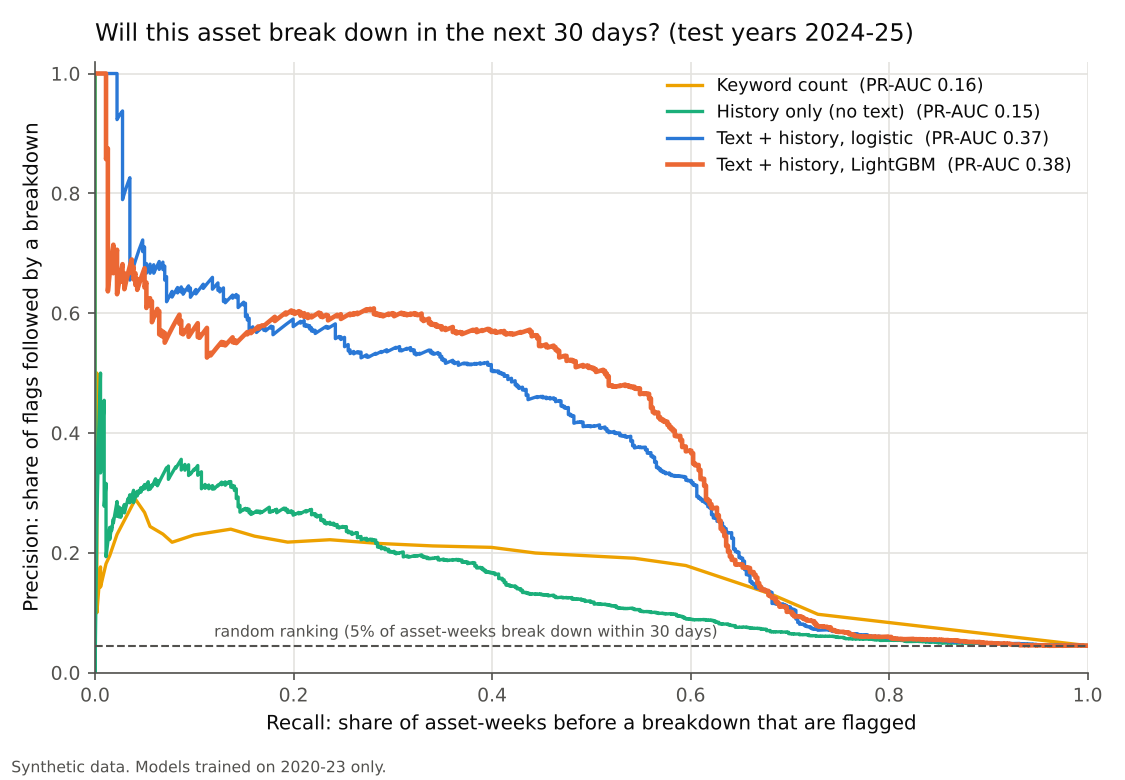

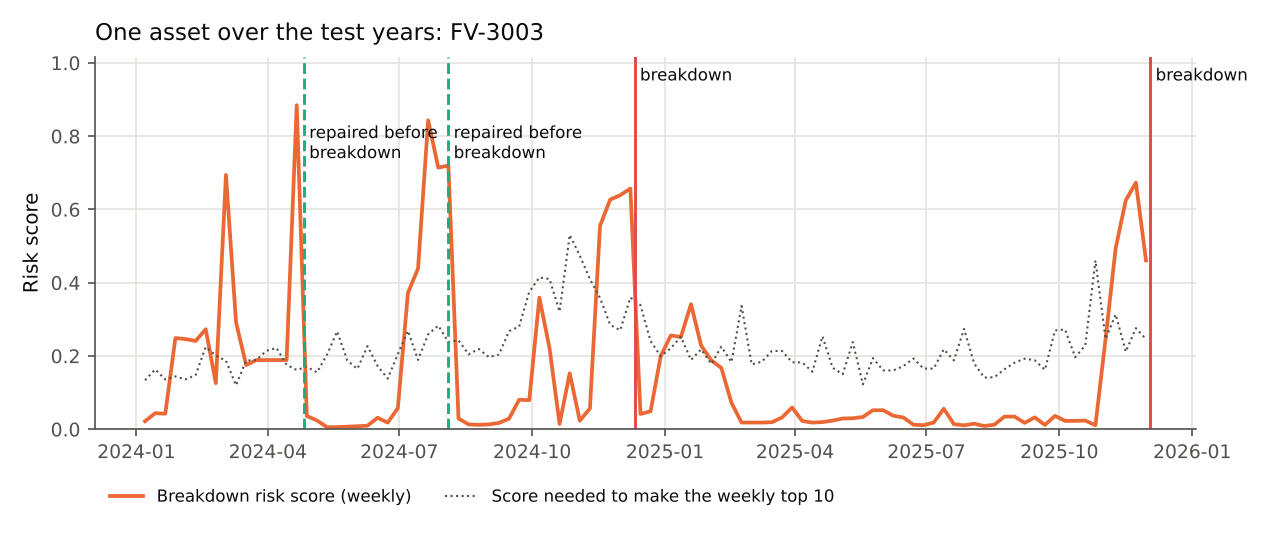

In [7]:
from src.utils import plots
plots.draw(test, scores, failures, episodes, chosen)
from IPython.display import Image, display
display(Image('reports/figures/precision_recall.png', width=700))
display(Image('reports/figures/asset_timeline.png', width=760))

## 9. Serve it
`uvicorn src.api.app:app --reload`, then open http://127.0.0.1:8000/docs. The same call from Python:

In [8]:
from fastapi.testclient import TestClient
from src.api.app import app
TestClient(app).post('/risk', json={'asset_type': 'pump', 'equipment_age_yr': 12, 'logs': [
    {'days_ago': 2, 'text': 'brg temp rising, now 88 C'}, {'days_ago': 6, 'text': 'vib incr on DE bearing'}]}).json()

{'risk_score': 0.764,
 'note': 'Score for ranking assets against each other; not a calibrated probability.',
 'evidence': 'vibration increasing on de bearing / bearing temperature rising, now 88 c'}